In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import binomtest, poisson
from statsmodels.stats.multitest import multipletests

In [2]:
orders = pd.read_csv("data/olist_orders_dataset.csv")
items = pd.read_csv("data/olist_order_items_dataset.csv")
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
sellers_raw = pd.read_csv("data/olist_sellers_dataset.csv")

for name, df in [("orders", orders), ("items", items), ("reviews", reviews), ("sellers", sellers_raw)]:
    print(f"{name:<8} {df.shape}")

print("\nSipariş durumları:")
print(orders["order_status"].value_counts())

orders   (99441, 8)
items    (112650, 7)
reviews  (99224, 7)
sellers  (3095, 4)

Sipariş durumları:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [3]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

one_day = pd.Timedelta(days=1)

shipped = items.merge(orders[orders["order_status"] == "delivered"], on="order_id")
shipped["carrier_vs_limit"] = (shipped["order_delivered_carrier_date"] - shipped["shipping_limit_date"]) / one_day
shipped["wait_time"] = (shipped["order_delivered_customer_date"] - shipped["order_purchase_timestamp"]) / one_day

delay_wait = shipped.groupby("seller_id").agg(
    delay_to_carrier=("carrier_vs_limit", "mean"),
    wait_time=("wait_time", "mean"),
).reset_index()
delay_wait["delay_to_carrier"] = delay_wait["delay_to_carrier"].clip(lower=0)

active = items.merge(orders[["order_id", "order_approved_at"]], on="order_id").groupby("seller_id").agg(
    date_first_sale=("order_approved_at", "min"),
    date_last_sale=("order_approved_at", "max"),
).reset_index()
active["months_on_olist"] = ((active["date_last_sale"] - active["date_first_sale"]) / pd.Timedelta(days=30)).round()

quantity = items.groupby("seller_id").agg(
    n_orders=("order_id", "nunique"),
    quantity=("order_item_id", "count"),
    sales=("price", "sum"),
).reset_index()
quantity["quantity_per_order"] = quantity["quantity"] / quantity["n_orders"]

seller_orders = items[["order_id", "seller_id"]].drop_duplicates()
seller_reviews = seller_orders.merge(reviews[["order_id", "review_score"]], on="order_id")
seller_reviews["one_star"] = (seller_reviews["review_score"] == 1).astype(int)
seller_reviews["five_star"] = (seller_reviews["review_score"] == 5).astype(int)
seller_reviews["low_star"] = (seller_reviews["review_score"] <= 2).astype(int)

review_stats = seller_reviews.groupby("seller_id").agg(
    share_of_one_stars=("one_star", "mean"),
    share_of_five_stars=("five_star", "mean"),
    review_score=("review_score", "mean"),
).reset_index()

sellers = (
    sellers_raw[["seller_id", "seller_city", "seller_state"]]
    .merge(delay_wait, on="seller_id")
    .merge(active, on="seller_id")
    .merge(quantity[["seller_id", "n_orders", "quantity", "quantity_per_order", "sales"]], on="seller_id")
    .merge(review_stats, on="seller_id")
)

print("sellers şekli:", sellers.shape, "| beklenen: (2967, 15)")
print("Medyan review_score:", round(sellers["review_score"].median(), 2), "| beklenen: 4.2")
print("Benzersiz seller_id:", sellers["seller_id"].is_unique)
print("Eksik değer:", int(sellers.isna().sum().sum()))
sellers.head()

sellers şekli: (2967, 15) | beklenen: (2967, 15)
Medyan review_score: 4.21 | beklenen: 4.2
Benzersiz seller_id: True
Eksik değer: 0


,seller_id,seller_city,seller_state,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,n_orders,quantity,quantity_per_order,sales,share_of_one_stars,share_of_five_stars,review_score
0,3442f8959a84dea7ee197c632cb2df15,campinas,SP,0.000000,13.018588,2017-05-05 16:25:11,2017-08-30 12:50:19,4.0,3,3,1.000,218.70,0.333333,0.333333,3.00
1,d1b65fc7debc3361ea86b5f14c68d2e2,mogi guacu,SP,0.000000,9.065716,2017-03-29 02:10:34,2018-06-06 20:15:21,14.0,40,41,1.025,11703.07,0.050000,0.725000,4.55
2,ce3ad9de960102d0677a81f5d0bb7b2d,rio de janeiro,RJ,0.000000,4.042292,2018-07-30 12:44:49,2018-07-30 12:44:49,0.0,1,1,1.000,158.00,0.000000,1.000000,5.00
3,c0f3eea2e14555b6faeea3dd58c1b1c3,sao paulo,SP,0.000000,5.667187,2018-08-03 00:44:08,2018-08-03 00:44:08,0.0,1,1,1.000,79.99,0.000000,1.000000,5.00
4,51a04a8a6bdcb23deccc82b0b80742cf,braganca paulista,SP,3.353727,35.314861,2017-11-14 12:15:25,2017-11-14 12:15:25,0.0,1,1,1.000,167.99,1.000000,0.000000,1.00


In [4]:
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered["delay_vs_expected"] = ((delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]) / one_day).clip(lower=0)
delivered["is_late"] = (delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]).astype(int)

delivery_stats = seller_orders.merge(delivered[["order_id", "delay_vs_expected", "is_late"]], on="order_id").groupby("seller_id").agg(
    delay_vs_expected=("delay_vs_expected", "mean"),
    share_late=("is_late", "mean"),
    n_delivered=("order_id", "nunique"),
).reset_index()

problem_status = ["canceled", "unavailable"]
seller_status = seller_orders.merge(orders[["order_id", "order_status"]], on="order_id")
seller_status["is_problem"] = seller_status["order_status"].isin(problem_status).astype(int)
problem_stats = seller_status.groupby("seller_id").agg(share_problem=("is_problem", "mean"), n_problem=("is_problem", "sum")).reset_index()

low_stats = seller_reviews.groupby("seller_id").agg(
    n_reviews=("review_score", "size"),
    n_low=("low_star", "sum"),
    share_of_low_stars=("low_star", "mean"),
).reset_index()

sellers_full = (
    sellers
    .merge(low_stats, on="seller_id", how="left")
    .merge(delivery_stats, on="seller_id", how="left")
    .merge(problem_stats, on="seller_id", how="left")
)

print("sellers_full şekli:", sellers_full.shape)
print("Eksik değer:", int(sellers_full.isna().sum().sum()))
print("Problemli sipariş durumları:", problem_status, "| toplam:", int(sellers_full["n_problem"].sum()))
sellers_full[["seller_id", "n_orders", "n_reviews", "review_score", "share_of_low_stars", "wait_time", "delay_vs_expected", "share_late", "share_problem"]].head()

sellers_full şekli: (2967, 23)
Eksik değer: 0
Problemli sipariş durumları: ['canceled', 'unavailable'] | toplam: 406


,seller_id,n_orders,n_reviews,review_score,share_of_low_stars,wait_time,delay_vs_expected,share_late,share_problem
0,3442f8959a84dea7ee197c632cb2df15,3,3,3.00,0.333333,13.018588,1.235586,0.333333,0.000
1,d1b65fc7debc3361ea86b5f14c68d2e2,40,40,4.55,0.050000,9.065716,0.066838,0.051282,0.025
2,ce3ad9de960102d0677a81f5d0bb7b2d,1,1,5.00,0.000000,4.042292,0.000000,0.000000,0.000
3,c0f3eea2e14555b6faeea3dd58c1b1c3,1,1,5.00,0.000000,5.667187,0.000000,0.000000,0.000
4,51a04a8a6bdcb23deccc82b0b80742cf,1,1,1.00,1.000000,35.314861,7.817743,1.000000,0.000


In [5]:
sellers_full.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
delay_to_carrier,2967.0,0.385636,0.0,0.0,0.0,0.0,45.434039,2.295812
wait_time,2967.0,12.139417,1.214178,8.287658,11.115143,14.231984,189.86316,7.069233
date_first_sale,2967,2017-10-23 20:09:55.342096,2016-09-15 12:16:38,2017-04-25 08:04:06.500000,2017-11-09 18:35:42,2018-04-24 18:21:19,2018-08-28 09:44:14,NaN
date_last_sale,2967,2018-04-25 09:37:50.292551,2016-10-06 15:44:56,2018-02-13 09:27:30,2018-07-19 14:30:17,2018-08-17 08:35:23,2018-09-03 17:40:06,NaN
months_on_olist,2967.0,6.116616,0.0,1.0,4.0,10.0,23.0,6.085524
n_orders,2967.0,33.650489,1.0,2.0,7.0,23.0,1854.0,107.182856
quantity,2967.0,37.897203,1.0,3.0,8.0,26.0,2033.0,121.514362
quantity_per_order,2967.0,1.157337,1.0,1.0,1.0,1.142857,15.0,0.439557
sales,2967.0,4568.852187,6.5,239.85,896.0,3583.995,229472.63,14191.836779
share_of_one_stars,2967.0,0.120886,0.0,0.0,0.058824,0.159043,1.0,0.188857


In [6]:
print("Satıcı başına sipariş medyanı:", sellers_full["n_orders"].median())
print("10'dan az siparişi olan satıcı oranı:", round((sellers_full["n_orders"] < 10).mean() * 100, 1), "%")
print("En büyük %10 satıcının sipariş payı:", round(sellers_full["n_orders"].nlargest(int(len(sellers_full) * 0.1)).sum() / sellers_full["n_orders"].sum() * 100, 1), "%")

Satıcı başına sipariş medyanı: 7.0
10'dan az siparişi olan satıcı oranı: 57.2 %
En büyük %10 satıcının sipariş payı: 67.5 %


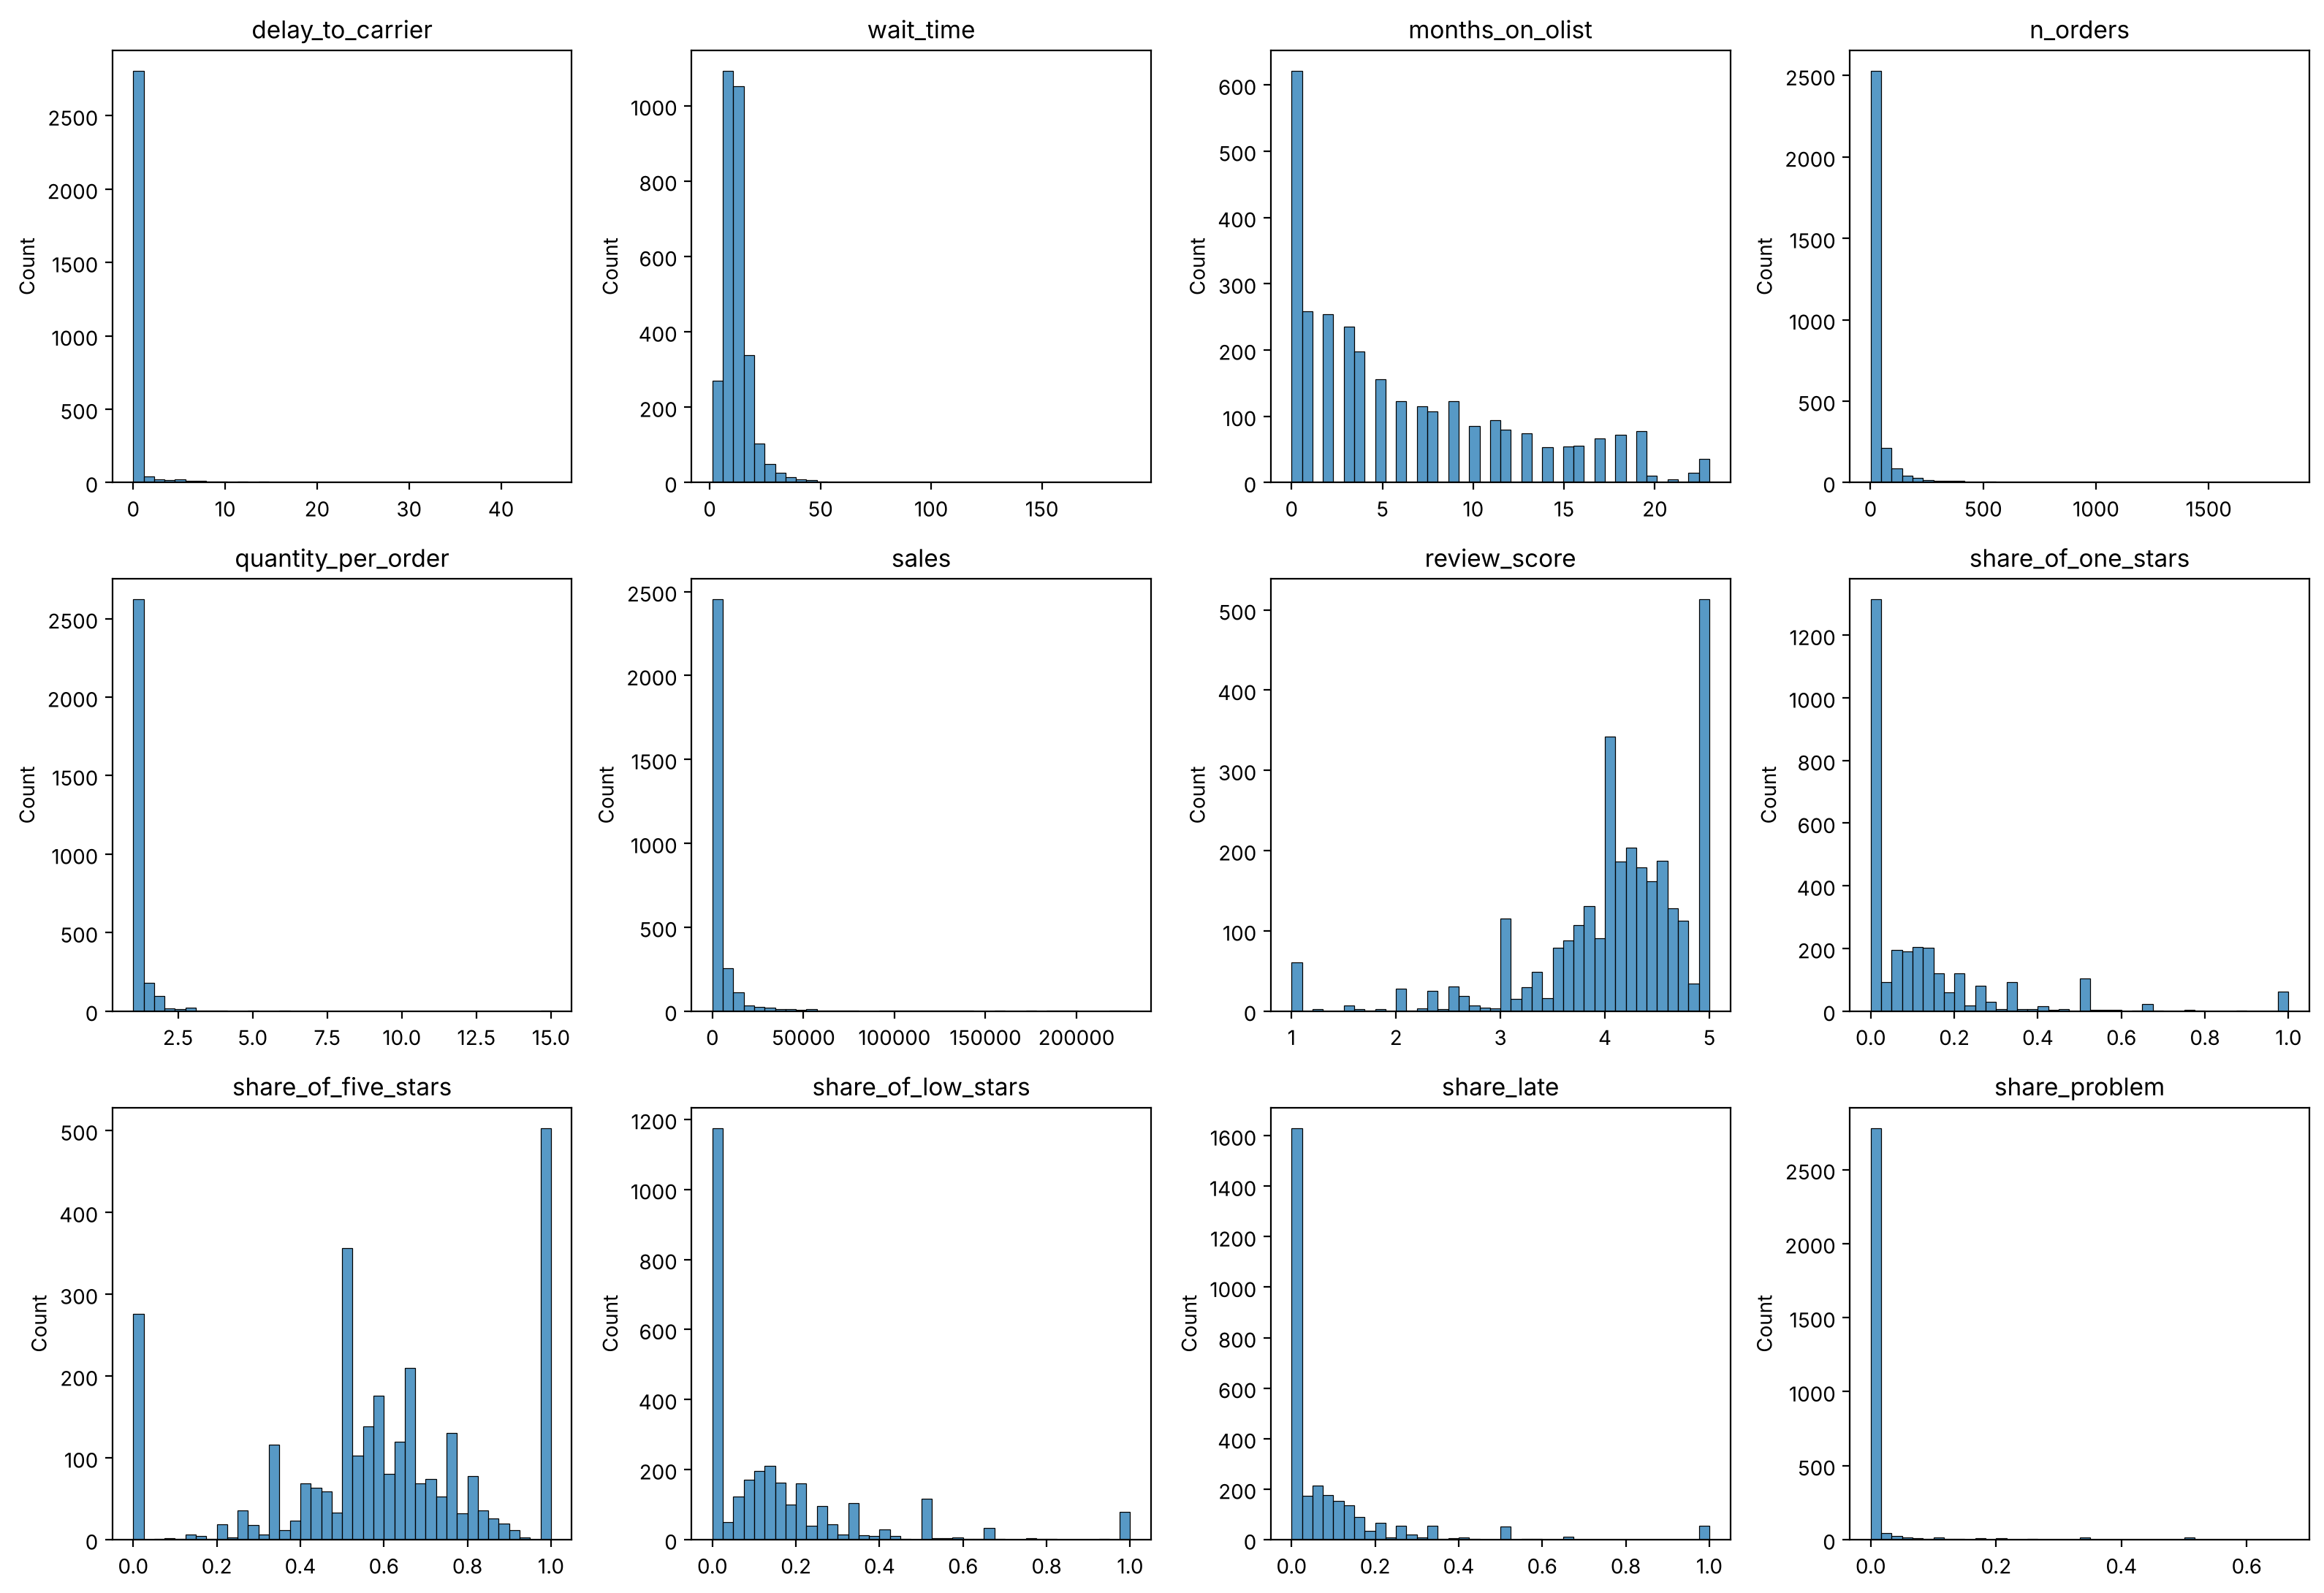

In [7]:
num_cols = ["delay_to_carrier", "wait_time", "months_on_olist", "n_orders", "quantity_per_order", "sales",
            "review_score", "share_of_one_stars", "share_of_five_stars", "share_of_low_stars", "share_late", "share_problem"]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(sellers_full[col], bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

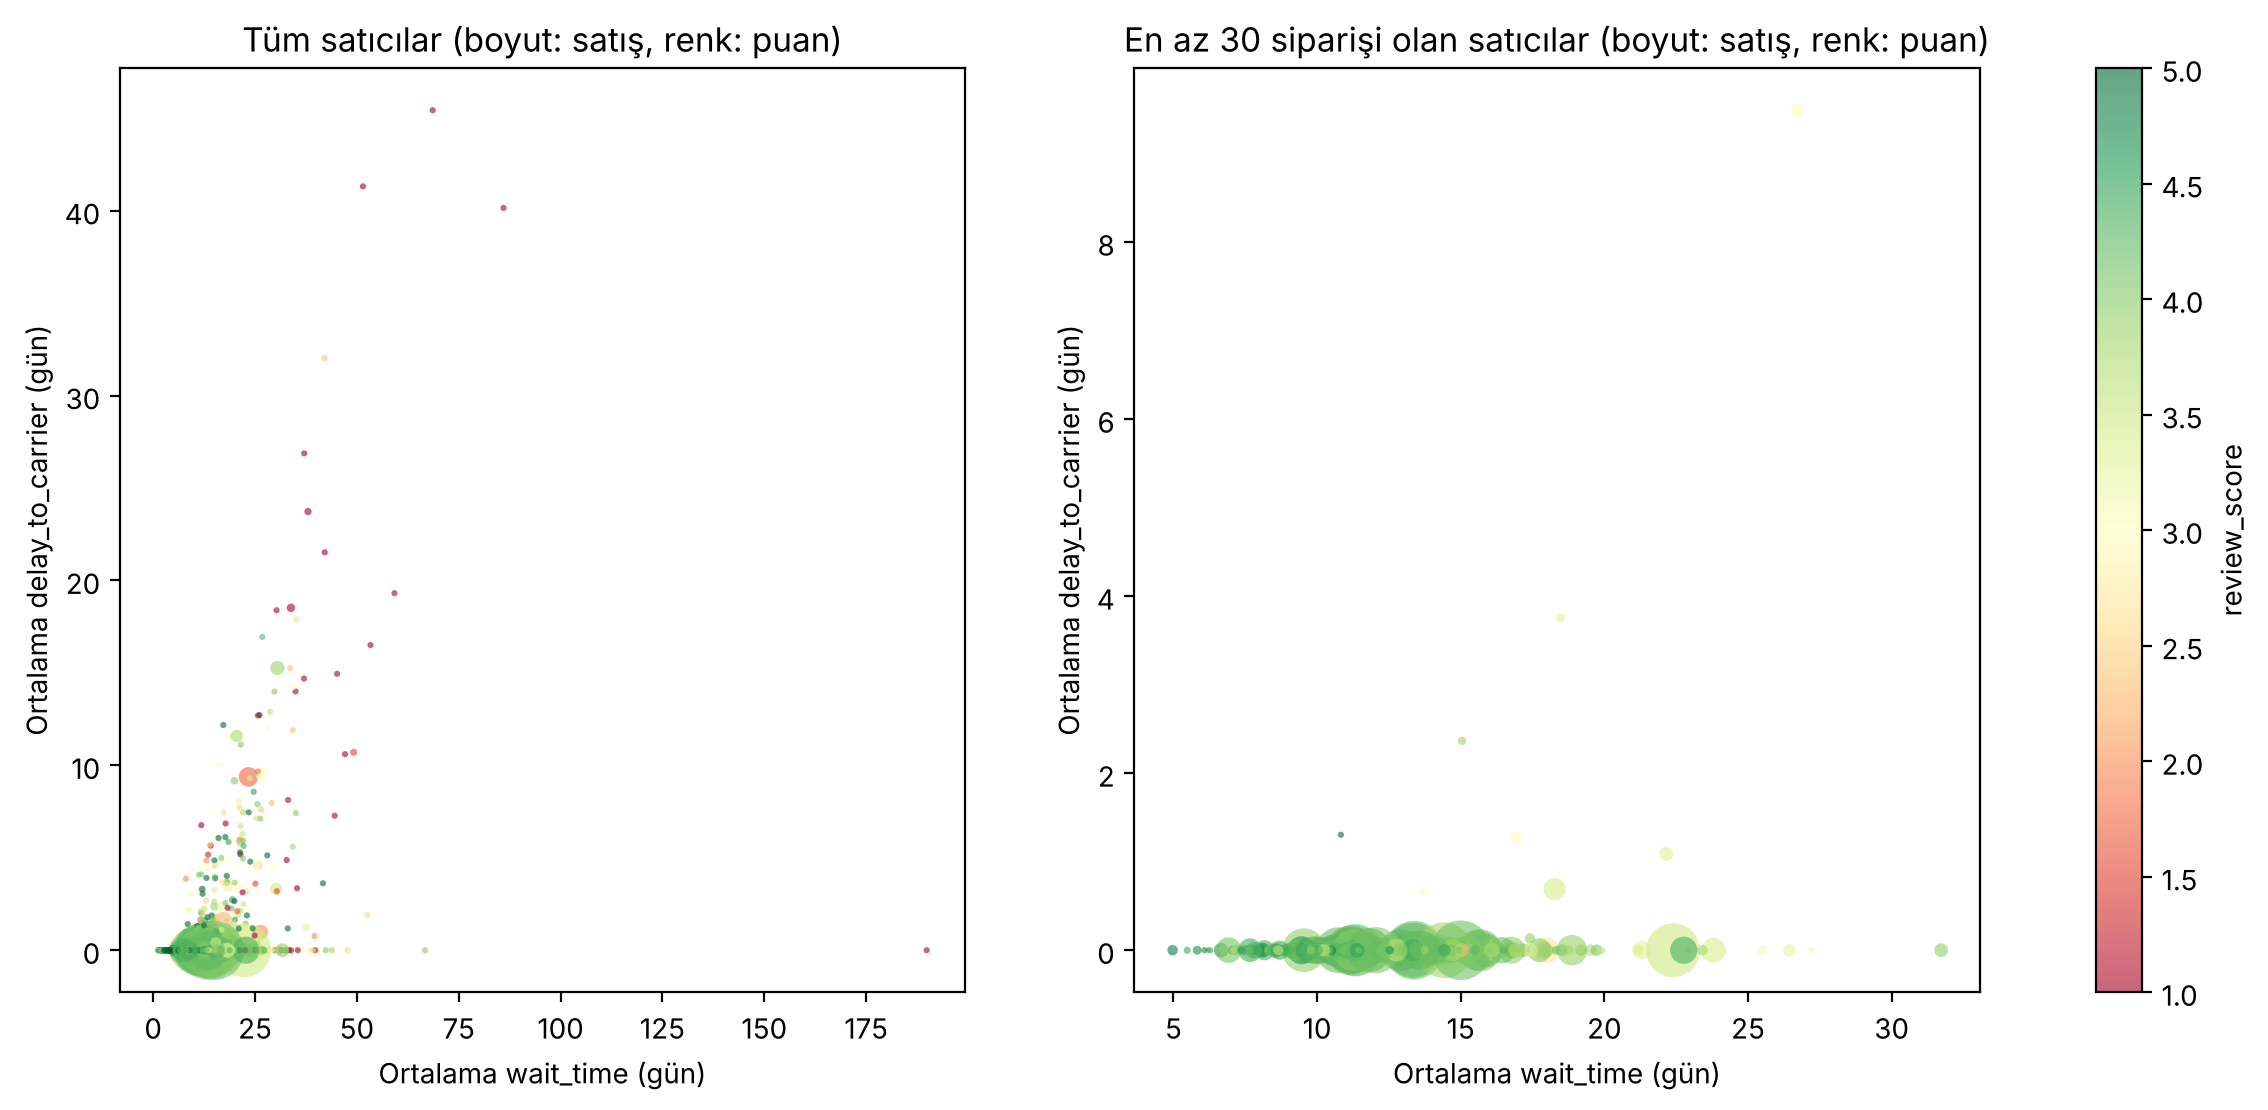

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, data, title in [
    (axes[0], sellers_full, "Tüm satıcılar"),
    (axes[1], sellers_full[sellers_full["n_orders"] >= 30], "En az 30 siparişi olan satıcılar"),
]:
    sc = ax.scatter(
        data["wait_time"], data["delay_to_carrier"],
        s=np.clip(data["sales"] / 500, 5, 600),
        c=data["review_score"], cmap="RdYlGn", vmin=1, vmax=5, alpha=0.6, edgecolors="none",
    )
    ax.set_xlabel("Ortalama wait_time (gün)")
    ax.set_ylabel("Ortalama delay_to_carrier (gün)")
    ax.set_title(title + " (boyut: satış, renk: puan)")
plt.colorbar(sc, ax=axes, label="review_score")
plt.show()

In [9]:
features = ["wait_time", "delay_to_carrier", "quantity_per_order", "n_orders", "sales", "months_on_olist"]

sellers_standardized = sellers_full.copy()
sellers_standardized[features] = (sellers_full[features] - sellers_full[features].mean()) / sellers_full[features].std()

model = smf.ols(f"review_score ~ {' + '.join(features)}", data=sellers_standardized).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.192
Method:                 Least Squares   F-statistic:                     118.8
Date:                Wed, 18 Nov 2026   Prob (F-statistic):          8.03e-135
Time:                        14:21:31   Log-Likelihood:                -3232.9
No. Observations:                2967   AIC:                             6480.
Df Residuals:                    2960   BIC:                             6522.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              4.1015      0.013    310.180      0.000       4.076       4.127
wait_time             -0.2739      0.015    -18.179      0.000      -0.303      -0.244
delay_to_carrier      -0.1241      0.015     -8.229      0.000      -0.154      -0.095
quantity_per_order    -0.0455      0.013     -3.436      0.001      -0.071      -0.020
n_orders              -0.0105      0.022     -0.470      0.638      -0.054       0.033
sales                  0.0097      0.022      0.437      0.662      -0.034       0.053
months_on_olist       -0.0074      0.015     -0.503      0.615      -0.036       0.021
==============================================================================
Omnibus:                      842.275   Durbin-Watson:                   2.045
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2966.037
Skew:                          -1.389   Prob(JB):                         0.00
Kurtosis:                       7.034   Cond. No.                         3.23
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

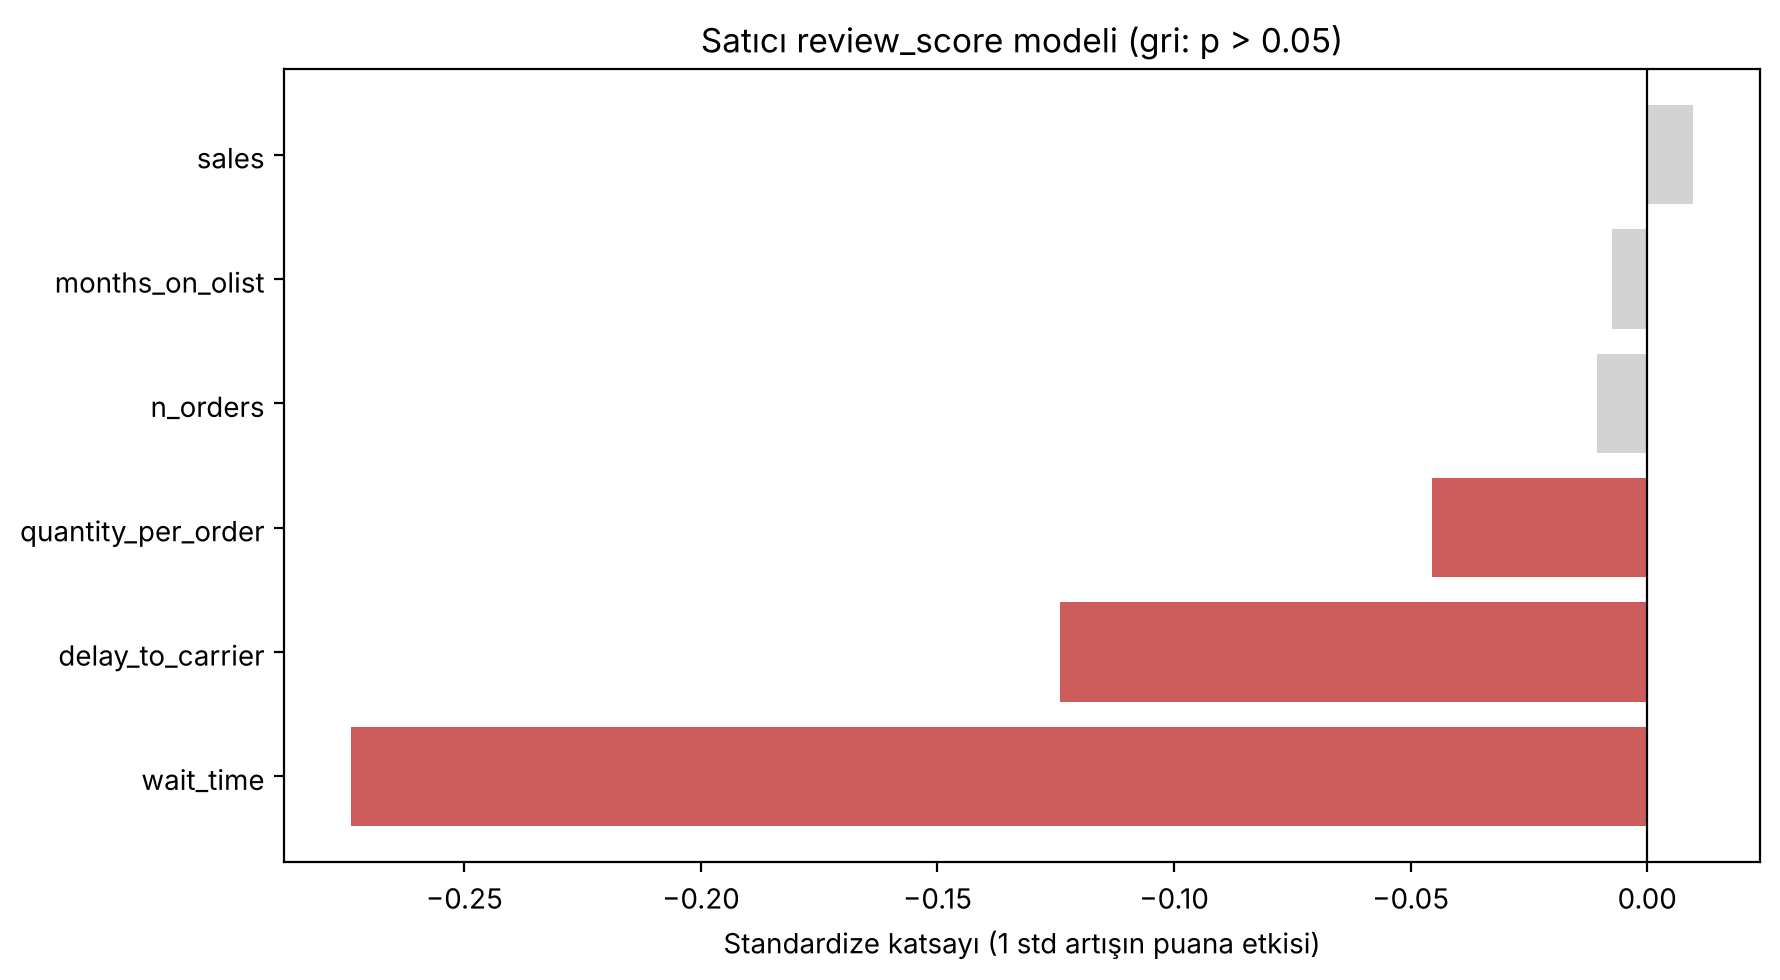

In [10]:
coefs = model.params.drop("Intercept").sort_values()
colors = ["indianred" if model.pvalues[c] < 0.05 else "lightgray" for c in coefs.index]

plt.figure(figsize=(9, 5))
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardize katsayı (1 std artışın puana etkisi)")
plt.title("Satıcı review_score modeli (gri: p > 0.05)")
plt.tight_layout()
plt.show()

R2: 0.194 | düzeltilmiş R2: 0.192
Kalıntı ortalaması: -0.0
RMSE: 0.719 | review_score std: 0.802


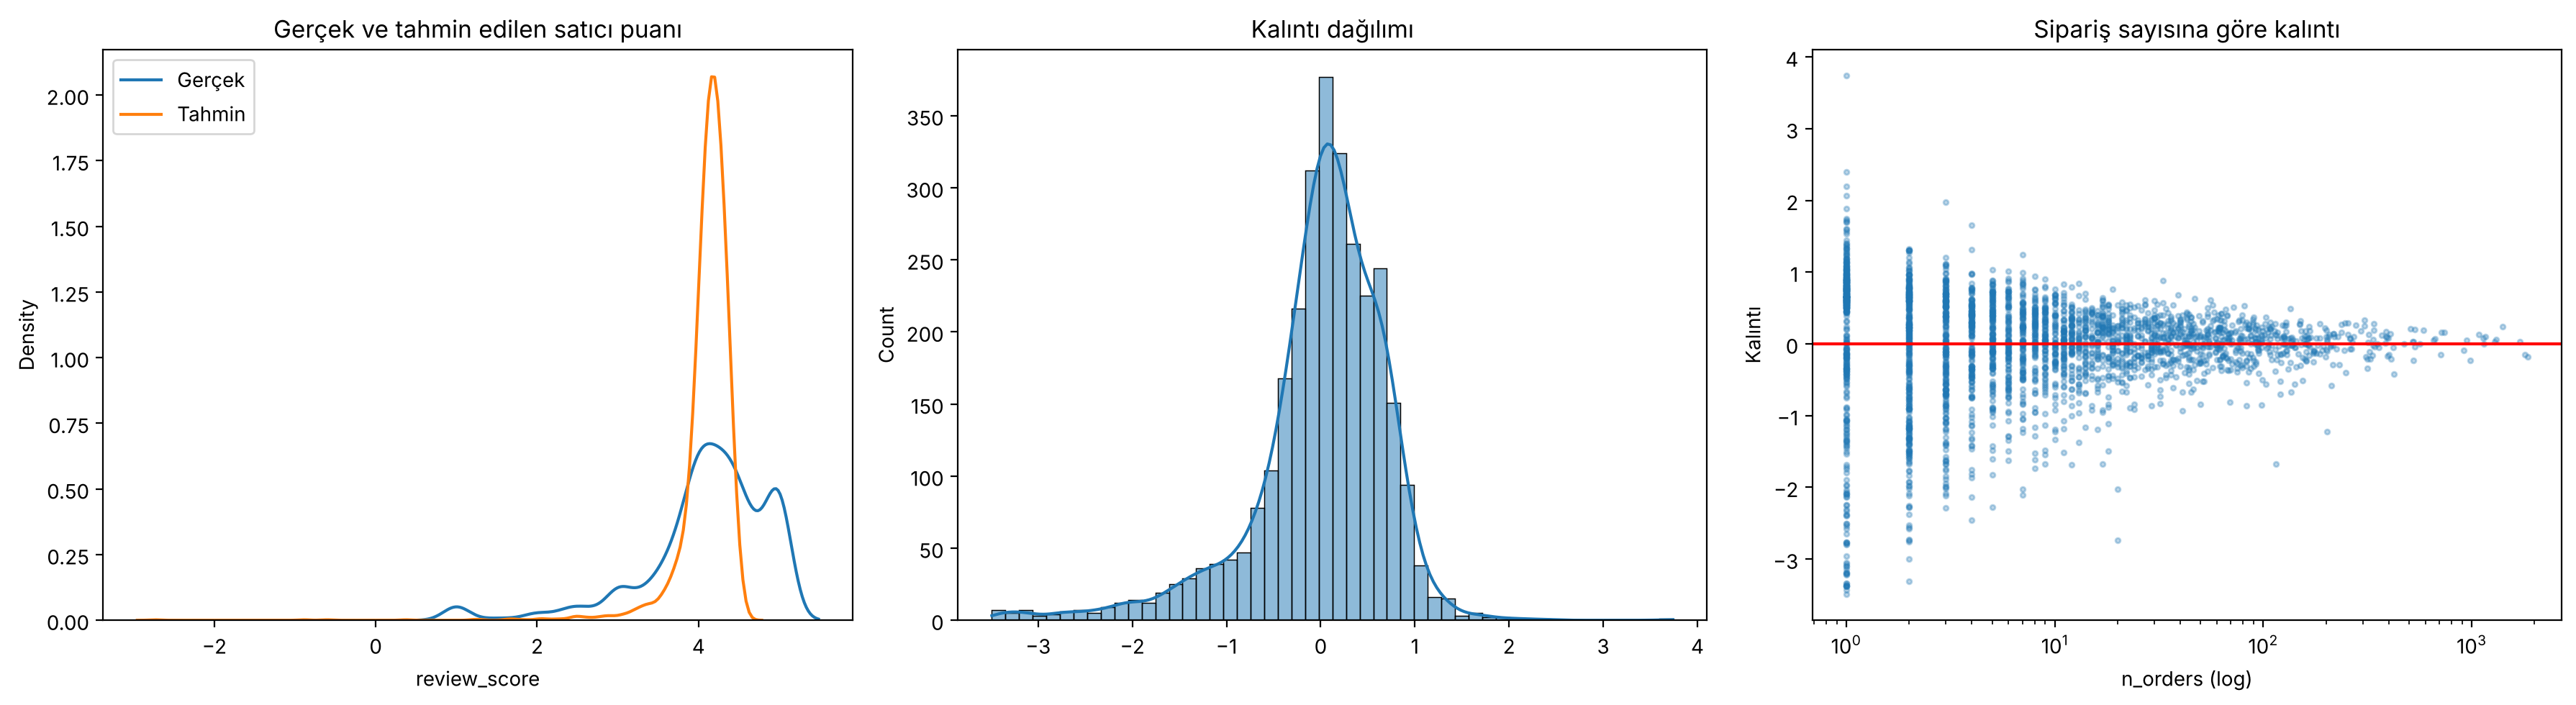

In [11]:
predicted = model.predict(sellers_standardized)
residuals = sellers_standardized["review_score"] - predicted

print("R2:", round(model.rsquared, 3), "| düzeltilmiş R2:", round(model.rsquared_adj, 3))
print("Kalıntı ortalaması:", round(residuals.mean(), 6))
print("RMSE:", round(np.sqrt((residuals ** 2).mean()), 3), "| review_score std:", round(sellers_full["review_score"].std(), 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(sellers_full["review_score"], label="Gerçek", ax=axes[0])
sns.kdeplot(predicted, label="Tahmin", ax=axes[0])
axes[0].set_title("Gerçek ve tahmin edilen satıcı puanı")
axes[0].legend()
sns.histplot(residuals, bins=50, kde=True, ax=axes[1])
axes[1].set_title("Kalıntı dağılımı")
axes[2].scatter(sellers_full["n_orders"], residuals, s=6, alpha=0.3)
axes[2].set_xscale("log")
axes[2].axhline(0, color="red")
axes[2].set_xlabel("n_orders (log)")
axes[2].set_ylabel("Kalıntı")
axes[2].set_title("Sipariş sayısına göre kalıntı")
plt.tight_layout()
plt.show()

In [12]:
def return_significative_coef(model, alpha=0.05):
    table = pd.DataFrame({"coef": model.params, "p_value": model.pvalues})
    return table[table["p_value"] < alpha].sort_values("coef")

state = "C(seller_state, Treatment(reference='SP'))"

state_model = smf.ols(f"review_score ~ {state}", data=sellers_full).fit()

print("Eyalet sayısı:", sellers_full["seller_state"].nunique(), "| R2:", round(state_model.rsquared, 3))
print("Eyalet dummy'lerinin ortak F-testi p-değeri:", round(state_model.f_pvalue, 4))
print("\nEyalet başına satıcı sayısı:")
print(sellers_full["seller_state"].value_counts().to_string())
print("\nAnlamlı katsayılar (referans eyalet: SP):")
return_significative_coef(state_model)

Eyalet sayısı: 22 | R2: 0.007
Eyalet dummy'lerinin ortak F-testi p-değeri: 0.4819

Eyalet başına satıcı sayısı:
seller_state
SP    1768
PR     333
MG     236
SC     184
RJ     163
RS     125
GO      39
DF      30
ES      22
BA      18
CE      12
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
PI       1
MA       1
AM       1
PA       1

Anlamlı katsayılar (referans eyalet: SP):


,coef,p_value
"C(seller_state, Treatment(reference='SP'))[T.AM]",-1.739509,0.030123
"C(seller_state, Treatment(reference='SP'))[T.ES]",0.338039,0.049409
Intercept,4.072842,0.000000


In [13]:
state_controls = ["wait_time", "wait_time + delay_to_carrier", "wait_time + delay_to_carrier + quantity_per_order"]

rows = []
for controls in state_controls:
    base = smf.ols(f"review_score ~ {controls}", data=sellers_full).fit()
    full = smf.ols(f"review_score ~ {state} + {controls}", data=sellers_full).fit()
    f_stat, f_p, _ = full.compare_f_test(base)
    sig = [i.split("[T.")[1].rstrip("]") for i in return_significative_coef(full).index if i.startswith("C(seller_state")]
    rows.append({"kontroller": controls, "R2": round(full.rsquared, 3), "eyalet_F": round(f_stat, 2), "eyalet_F_p": round(f_p, 4), "anlamlı_eyaletler (SP'ye göre)": ", ".join(sig)})

pd.DataFrame(rows)

,kontroller,R2,eyalet_F,eyalet_F_p,anlamlı_eyaletler (SP'ye göre)
0,wait_time,0.180,1.32,0.1473,"PR, MG, SC, RS, ES"
1,wait_time + delay_to_carrier,0.198,1.22,0.2221,"PR, MG, SC, RS, ES"
2,wait_time + delay_to_carrier + quantity_per_order,0.201,1.22,0.2214,"PR, MG, SC, RS, ES"


In [14]:
state_wait = smf.ols(f"review_score ~ {state} + wait_time", data=sellers_full).fit()
sig = return_significative_coef(state_wait)
sig.index = [i.replace("C(seller_state, Treatment(reference='SP'))", "state") for i in sig.index]
print(sig.round(4))

by_state = sellers_full.groupby("seller_state").agg(satici=("seller_id", "count"), review_score=("review_score", "mean"), wait_time=("wait_time", "mean"))
by_state.loc[["SP", "PR", "MG", "SC", "RS", "ES", "RJ"]].round(2)

               coef  p_value
wait_time   -0.0476   0.0000
state[T.PR]  0.0986   0.0236
state[T.MG]  0.1181   0.0195
state[T.SC]  0.1473   0.0092
state[T.RS]  0.1568   0.0203
state[T.ES]  0.3706   0.0178
Intercept    4.6329   0.0000


,satici,review_score,wait_time
seller_state,,,
SP,1768,4.07,11.76
PR,333,4.16,11.95
MG,236,4.14,12.77
SC,184,4.17,12.88
RS,125,4.15,13.45
ES,22,4.41,12.44
RJ,163,4.10,11.73


In [15]:
platform_low = seller_reviews["low_star"].mean()
platform_late = delivered["is_late"].mean()
platform_problem = seller_status["is_problem"].mean()

print(f"Platform düşük puan (1-2) oranı: {platform_low:.3f}")
print(f"Platform geç teslim oranı: {platform_late:.3f}")
print(f"Platform problemli sipariş oranı: {platform_problem:.4f}")

def binom_pvalue(k, n, p):
    return binomtest(int(k), int(n), p, alternative="greater").pvalue if n > 0 else 1.0

sellers_full["n_late"] = (sellers_full["share_late"] * sellers_full["n_delivered"]).round().astype(int)
sellers_full["p_low"] = [binom_pvalue(k, n, platform_low) for k, n in zip(sellers_full["n_low"], sellers_full["n_reviews"])]
sellers_full["p_late"] = [binom_pvalue(k, n, platform_late) for k, n in zip(sellers_full["n_late"], sellers_full["n_delivered"])]
sellers_full["p_problem"] = [binom_pvalue(k, n, platform_problem) for k, n in zip(sellers_full["n_problem"], sellers_full["n_orders"])]

for flag, pcol in [("flag_low", "p_low"), ("flag_late", "p_late"), ("flag_problem", "p_problem")]:
    sellers_full[flag] = multipletests(sellers_full[pcol], alpha=0.05, method="fdr_bh")[0]

print("\nPlatform ortalamasından anlamlı derecede kötü satıcı sayısı (binom testi, FDR %5):")
print(sellers_full[["flag_low", "flag_late", "flag_problem"]].sum().to_string())

Platform düşük puan (1-2) oranı: 0.147
Platform geç teslim oranı: 0.081
Platform problemli sipariş oranı: 0.0047



Platform ortalamasından anlamlı derecede kötü satıcı sayısı (binom testi, FDR %5):
flag_low        42
flag_late       22
flag_problem     8


In [16]:
order_level = (
    seller_orders
    .merge(delivered[["order_id", "order_purchase_timestamp", "order_delivered_customer_date", "delay_vs_expected"]], on="order_id")
    .merge(reviews[["order_id", "review_score"]], on="order_id")
)
order_level["wait_time"] = (order_level["order_delivered_customer_date"] - order_level["order_purchase_timestamp"]) / one_day
order_level = order_level.dropna(subset=["wait_time"])
order_level["low_star"] = (order_level["review_score"] <= 2).astype(int)

delivery_logit = smf.logit("low_star ~ wait_time + delay_vs_expected", data=order_level).fit(disp=False)
order_level["p_low_expected"] = delivery_logit.predict(order_level)

print("Sipariş düzeyi satır:", len(order_level), "| pseudo R2:", round(delivery_logit.prsquared, 3))
print(np.exp(delivery_logit.params).round(4).rename("odds_ratio").to_string())

excess = order_level.groupby("seller_id").agg(
    low_observed=("low_star", "sum"),
    low_expected=("p_low_expected", "sum"),
).reset_index()
excess["p_excess"] = poisson.sf(excess["low_observed"] - 1, excess["low_expected"])
excess["flag_excess"] = multipletests(excess["p_excess"], alpha=0.05, method="fdr_bh")[0]
excess["excess_low"] = excess["low_observed"] - excess["low_expected"]

sellers_full = sellers_full.merge(excess, on="seller_id", how="left")
sellers_full[["low_observed", "low_expected", "excess_low", "p_excess"]] = sellers_full[["low_observed", "low_expected", "excess_low", "p_excess"]].fillna({"low_observed": 0, "low_expected": 0, "excess_low": 0, "p_excess": 1})
sellers_full["flag_excess"] = sellers_full["flag_excess"].fillna(False).astype(bool)

print("\nTeslimat süresine göre beklenenden anlamlı fazla kötü yorum alan satıcı:", int(sellers_full["flag_excess"].sum()))
print(pd.crosstab(sellers_full["flag_low"], sellers_full["flag_excess"], rownames=["platformdan kötü"], colnames=["beklenenden kötü"]))

Sipariş düzeyi satır: 97694 | pseudo R2: 0.102
Intercept            0.0662
wait_time            1.0533
delay_vs_expected    1.1058

Teslimat süresine göre beklenenden anlamlı fazla kötü yorum alan satıcı: 16
beklenenden kötü  False  True 
platformdan kötü              
False              2923      2
True                 28     14


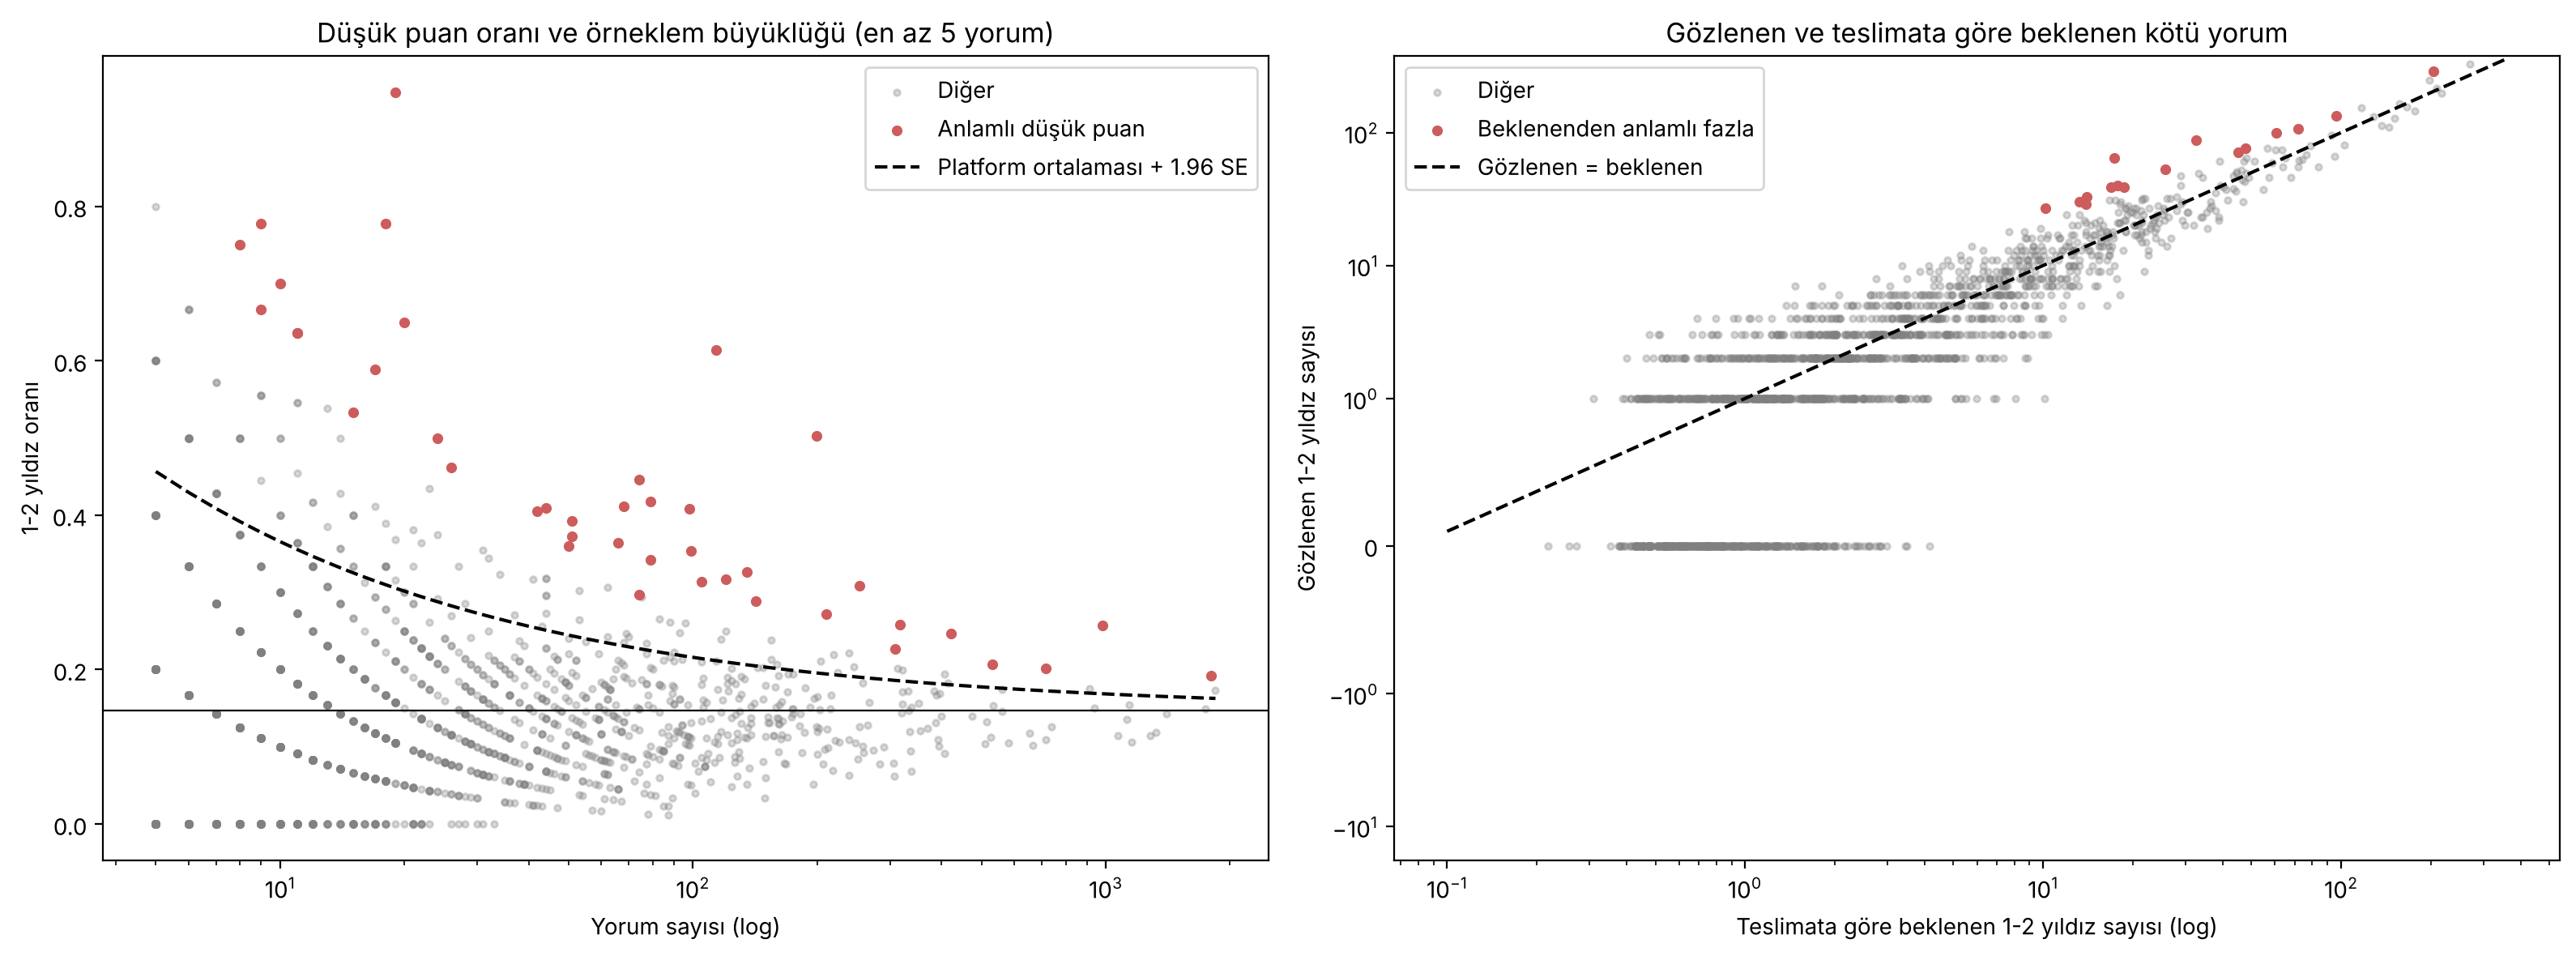

In [17]:
sample = sellers_full[sellers_full["n_reviews"] >= 5]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(sample["n_reviews"], sample["share_of_low_stars"], s=8, alpha=0.3, color="gray", label="Diğer")
axes[0].scatter(sample.loc[sample["flag_low"], "n_reviews"], sample.loc[sample["flag_low"], "share_of_low_stars"], s=14, color="indianred", label="Anlamlı düşük puan")
n_grid = np.arange(5, sample["n_reviews"].max() + 1)
axes[0].plot(n_grid, platform_low + 1.96 * np.sqrt(platform_low * (1 - platform_low) / n_grid), color="black", linestyle="--", label="Platform ortalaması + 1.96 SE")
axes[0].axhline(platform_low, color="black", linewidth=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("Yorum sayısı (log)")
axes[0].set_ylabel("1-2 yıldız oranı")
axes[0].set_title("Düşük puan oranı ve örneklem büyüklüğü (en az 5 yorum)")
axes[0].legend()

lim = sample[["low_expected", "low_observed"]].max().max() * 1.1
axes[1].scatter(sample["low_expected"], sample["low_observed"], s=8, alpha=0.3, color="gray", label="Diğer")
axes[1].scatter(sample.loc[sample["flag_excess"], "low_expected"], sample.loc[sample["flag_excess"], "low_observed"], s=14, color="indianred", label="Beklenenden anlamlı fazla")
axes[1].plot([0.1, lim], [0.1, lim], color="black", linestyle="--", label="Gözlenen = beklenen")
axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_xlabel("Teslimata göre beklenen 1-2 yıldız sayısı (log)")
axes[1].set_ylabel("Gözlenen 1-2 yıldız sayısı")
axes[1].set_title("Gözlenen ve teslimata göre beklenen kötü yorum")
axes[1].legend()
plt.tight_layout()
plt.show()

In [18]:
def segment(row):
    if row["flag_low"] and row["flag_excess"]:
        return "1 - Kaldırma/inceleme adayı"
    if row["flag_low"] or row["flag_late"]:
        return "2 - Lojistik destek"
    if row["flag_problem"]:
        return "3 - İptal/stok sorunu"
    if row["flag_excess"]:
        return "4 - İzlenecek"
    return "5 - Normal"

sellers_full["segment"] = sellers_full.apply(segment, axis=1)

summary = sellers_full.groupby("segment").agg(
    satici=("seller_id", "count"),
    siparis=("n_orders", "sum"),
    satis=("sales", "sum"),
    dusuk_yorum=("n_low", "sum"),
    fazla_dusuk=("excess_low", "sum"),
    ort_puan=("review_score", "median"),
    dusuk_oran=("share_of_low_stars", "median"),
    wait_time=("wait_time", "median"),
    delay_to_carrier=("delay_to_carrier", "median"),
    gec_oran=("share_late", "median"),
    problem_oran=("share_problem", "median"),
)
summary["satis_payi_%"] = summary["satis"] / summary["satis"].sum() * 100
summary["dusuk_yorum_payi_%"] = summary["dusuk_yorum"] / summary["dusuk_yorum"].sum() * 100
summary.drop(columns="satis").round(2)

,satici,siparis,dusuk_yorum,fazla_dusuk,ort_puan,dusuk_oran,wait_time,delay_to_carrier,gec_oran,problem_oran,satis_payi_%,dusuk_yorum_payi_%
segment,,,,,,,,,,,,
1 - Kaldırma/inceleme adayı,14,3401,969,410.45,3.44,0.31,14.58,0.0,0.11,0.00,2.19,6.69
2 - Lojistik destek,40,6804,1516,202.03,3.30,0.36,18.06,0.0,0.19,0.00,8.05,10.47
3 - İptal/stok sorunu,6,69,28,3.49,2.92,0.47,16.55,0.0,0.12,0.38,0.15,0.19
4 - İzlenecek,2,1975,349,104.19,3.78,0.21,10.19,0.0,0.04,0.00,1.03,2.41
5 - Normal,2905,87592,11622,-720.16,4.23,0.09,11.03,0.0,0.00,0.00,88.57,80.24


In [19]:
cols = ["seller_id", "seller_state", "n_orders", "review_score", "share_of_low_stars", "low_observed", "low_expected", "wait_time", "delay_to_carrier", "share_late", "share_problem", "sales"]

for seg in ["1 - Kaldırma/inceleme adayı", "2 - Lojistik destek", "3 - İptal/stok sorunu"]:
    print(f"\n{seg}")
    print(sellers_full.loc[sellers_full["segment"] == seg, cols].sort_values("n_orders", ascending=False).head(8).round(2).to_string(index=False))


1 - Kaldırma/inceleme adayı
                       seller_id seller_state  n_orders  review_score  share_of_low_stars  low_observed  low_expected  wait_time  delay_to_carrier  share_late  share_problem    sales
cca3071e3e9bb7d12640c9fbe2301306           SP       712          3.85                0.20         134.0         96.54      14.24              0.00        0.06           0.00 64009.89
d2374cbcbb3ca4ab1086534108cc3ab7           SP       524          3.75                0.21         106.0         71.83      14.30              0.00        0.06           0.00 21223.92
1835b56ce799e6a4dc4eddc053f04066           SP       423          3.64                0.25         100.0         60.42      12.77              0.00        0.12           0.00 33344.21
897060da8b9a21f655304d50fd935913           SP       317          3.62                0.26          71.0         45.01      14.86              0.00        0.12           0.00 23023.92
88460e8ebdecbfecb5f9601833981930           PR       248 

In [20]:
removed = sellers_full["segment"] == "1 - Kaldırma/inceleme adayı"
rest = sellers_full[~removed]

low_after = rest["n_low"].sum() / rest["n_reviews"].sum()
lost_sales = sellers_full.loc[removed, "sales"].sum() / sellers_full["sales"].sum()
lost_low = sellers_full.loc[removed, "n_low"].sum() / sellers_full["n_low"].sum()

print(f"Kaldırma adayı satıcı sayısı: {int(removed.sum())}")
print(f"Platform düşük puan oranı: {platform_low * 100:.2f}% -> {low_after * 100:.2f}%")
print(f"Ortadan kalkan 1-2 yıldızlı yorum payı: {lost_low * 100:.1f}%")
print(f"Kaybedilen satış payı: {lost_sales * 100:.1f}%")

Kaldırma adayı satıcı sayısı: 14
Platform düşük puan oranı: 14.65% -> 14.04%
Ortadan kalkan 1-2 yıldızlı yorum payı: 6.7%
Kaybedilen satış payı: 2.2%


## Sonuç

- **Satıcı veri seti:** `sellers`, `orders`, `order_items` ve `order_reviews` birleştirilerek her satırı bir satıcı olan tablo kuruldu. Temel tablo (`sellers`) şablonun beklediği 15 sütunu içeriyor: 2967 satır, medyan `review_score` 4.21, benzersiz `seller_id`, eksik değer yok. Yalnızca teslim edilmiş siparişi ve yorumu olan satıcılar tutuldu (iç birleştirme). `sellers_full` buna görevde istenen metrikleri ekliyor: yorum sayısı, 1-2 yıldız oranı (`share_of_low_stars`), ortalama `delay_vs_expected`, geç teslim oranı (`share_late`) ve problemli sipariş oranı (`share_problem`). Olist verisinde iade bilgisi olmadığı için problemli sipariş, `canceled` veya `unavailable` durumundaki sipariş olarak tanımlandı (406 sipariş). `delay_to_carrier`, satıcının ortalama kargoya teslim gecikmesi (önce ortalama alınıp sonra 0'ın altı kırpıldığı için çoğu satıcıda 0).

- **Dağılımlar:** Satıcı başına sipariş medyanı 7, satıcıların %57.2'sinin 10'dan az siparişi var, en büyük %10'luk dilim siparişlerin %67.5'ini yapıyor. Az siparişli satıcıların puanları (1.0 veya 5.0 gibi) tek tük siparişe dayandığı için uç değerlerde toplanıyor. Bu yüzden ham ortalama puana göre sıralama yapmak yanıltıcı.

- **OLS (satıcı puanı):** Standardize 6 özellikle R² = 0.194. En güçlü etki `wait_time` (-0.27), sonra `delay_to_carrier` (-0.12) ve `quantity_per_order` (-0.05), üçü de p < 0.01. `n_orders`, `sales` ve `months_on_olist` anlamlı değil (p > 0.6): satıcının büyüklüğü ve platformdaki süresi, teslimat kontrol edildiğinde puanı açıklamıyor. RMSE 0.72, puanın standart sapması 0.80. Kalıntılar az siparişli satıcılarda çok geniş, büyüdükçe daralıyor: model eşit ağırlıklı satıcılarla kurulduğu için 1-2 siparişlik satıcıların gürültüsü sonucu etkiliyor.

- **Eyalet etkisi:** Tek başına `seller_state` modeli R² = 0.007, eyalet dummy'lerinin ortak F-testi p = 0.48. `wait_time` eklenince PR, MG, SC, RS ve ES tek tek SP'den anlamlı derecede iyi görünüyor (+0.10 ile +0.37), ama ortak F-testi yine anlamlı değil (p = 0.15; `delay_to_carrier` ve `quantity_per_order` eklenince p = 0.22). 21 karşılaştırmada birkaç anlamlı sonuç şans eseri de çıkabilir, ayrıca anlamlılık referans eyalete bağlı (şablondaki gibi alfabetik referans olarak tek satıcılı bir eyalet alınırsa sonuç tamamen değişiyor). Sonuç: eyaletin `wait_time` dışında puana etkisi olduğuna dair yeterli kanıt yok. SP satıcılarının teslimat süresine göre biraz düşük puan alması ise izlenmeye değer bir hipotez.

- **Kötü performansın sistematik tespiti:** Ham oranlara eşik koymak yerine her satıcı platform ortalamasıyla binom testiyle karşılaştırıldı ve 2967 test yapıldığı için Benjamini-Hochberg düzeltmesi (FDR %5) uygulandı. Platform ortalamaları: düşük puan %14.7, geç teslim %8.1, problemli sipariş %0.47. Anlamlı derecede kötü satıcı: düşük puanda 42, geç teslimde 22, problemli siparişte 8. Grafikte görüldüğü gibi bu yöntem az yorumlu satıcılarda daha yüksek oran istiyor; 5 yorumdan 3'ü kötü olan satıcı işaretlenmezken 1806 yorumda %19 oranlı satıcı işaretleniyor.

- **Teslimatla açıklanamayan kötü yorum:** Sipariş düzeyinde `low_star ~ wait_time + delay_vs_expected` lojistik modeli kuruldu (her ek bekleme günü 1-2 yıldız odds'unu %5.3, her ek gecikme günü %10.6 artırıyor). Bu modelle her satıcının teslimat sürelerine göre beklenen kötü yorum sayısı hesaplanıp gözlenenle Poisson testiyle karşılaştırıldı (FDR %5). 16 satıcı beklenenden anlamlı fazla kötü yorum alıyor; bunların 14'ü platform ortalamasından da kötü. Bu satıcılarda sorun teslimat süresiyle açıklanamıyor, ürün, açıklama veya hizmet kalitesine işaret ediyor.

- **Satıcı grupları:**
  - **1 - Kaldırma/inceleme adayı (14 satıcı):** Hem platformdan hem teslimata göre beklenenden kötü. Siparişlerin %3.4'ü, satışların %2.2'si, kötü yorumların %6.7'si. Medyan puan 3.44, teslimat süreleri platforma yakın (medyan 14.6 gün). Kötü yorumların yaklaşık 410'u teslimatla açıklanamayan fazlalık.
  - **2 - Lojistik destek (40 satıcı):** Kötü puanları ya da geç teslimleri var ama kötü yorumları teslimat süreleriyle büyük ölçüde açıklanıyor. Medyan bekleme 18.1 gün, geç teslim oranı %19. Satışların %8.1'i, kötü yorumların %10.5'i. Aralarında platformun en büyük satıcıları var (ör. 1806 ve 1132 siparişli iki satıcı), kaldırmak yerine kargo süreçlerinde desteklenmeleri gerekiyor.
  - **3 - İptal/stok sorunu (6 satıcı):** Yalnızca 69 sipariş, ama medyan problemli sipariş oranı %38. Stok yönetimi uyarısı, tekrar ederse askıya alma.
  - **4 - İzlenecek (2 satıcı):** Platform ortalamasından anlamlı kötü değil ama hızlı teslimatına rağmen (medyan 10.2 gün, %4 geç) beklenenden fazla kötü yorum alıyor. Toplam 1975 sipariş, kötü yorumların %2.4'ü.
  - **5 - Normal (2905 satıcı):** Satışların %88.6'sı, ama kötü yorumların da %80.2'si.

- **Kaldırma senaryosu:** 1. gruptaki 14 satıcı çıkarılırsa (müşterilerin başka satıcıdan aynı memnuniyetle alacağı varsayımıyla) platform düşük puan oranı %14.65'ten %14.04'e iner, kötü yorumların %6.7'si ortadan kalkar, satışların %2.2'si kaybedilir.

- **Hipotezler ve öneriler:**
  - Kötü yorumların %80'i "normal" satıcılardan geliyor, yani sorun birkaç kötü satıcıda yoğunlaşmıyor, platform geneline yayılmış durumda. Satıcı kaldırmak sınırlı etkili; asıl kaldıraç teslimat süresi (satıcı puanını en çok açıklayan değişken).
  - 1. gruptaki satıcılar için kaldırmadan önce yorum metinleri ve ürün kategorileri incelenmeli; sorun tek bir üründe ise ürünü kaldırmak satıcıyı kaldırmaktan daha az satış kaybettirir.
  - 2. gruptaki büyük satıcılar için daha yakın depo, hızlı kargo anlaşması veya gerçekçi teslim tarihi tahmini (gecikme, bekleme süresinden daha fazla kötü yoruma yol açıyor) denenebilir.
  - Yeni satıcılar için ilk siparişlerde kalite kontrolü önerilebilir, çünkü az siparişli satıcıların performansı istatistiksel olarak ancak birkaç düzine siparişten sonra değerlendirilebiliyor.

- **Sınırlılıklar:** Bir siparişte birden fazla satıcı varsa siparişin yorumu hepsine yazıldı (yorumun hangi satıcıya ait olduğu bilinmiyor). Kaldırma senaryosu, o siparişlerin başka satıcılara iyi puanla gideceğini varsayıyor. Testler platform ortalamasına göre; kategori farkları (bazı kategoriler doğal olarak daha çok kötü yorum alıyor olabilir) kontrol edilmedi. Teslimata göre beklenen kötü yorum modeli yalnızca iki değişkenli ve pseudo R² = 0.10. Veri gözlemsel, ilişkiler nedensellik göstermiyor.